In [1]:
import sys
!{sys.executable} -m pip install -q pandas matplotlib

# 04. Provincial scorecard: the same country, very different economies

The national average hides the real story. Guangdong's economy alone is bigger than most countries. Tibet's is smaller than a single large Chinese city. This notebook compares all 31 mainland provincial divisions on GDP, GDP per person, growth, urbanization, and long-run change, and it is honest about what could not be compared.

Two labels matter. GDP figures are from NBS data via a Wikipedia compilation: 2024 is revised, 2025 is preliminary. GDP per person here is approximate: 2024 GDP divided by the mid-2022 resident population, because a 2024 provincial population table was not fetched for this build. Populations move, so treat the per person ranking as close, not exact. Urbanization rates are computed from the same mid-2022 NBS table: urban residents divided by total residents.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
PROC = "../data/processed"
CHARTS = "../charts"

prov = pd.read_csv(f"{PROC}/provinces.csv")
print("provinces:", len(prov))
print()
top = prov.sort_values("gdp_2024_m_cny", ascending=False)
print("Top 10 by 2024 GDP (million CNY):")
print(top[["province", "gdp_2024_m_cny", "share_of_national_2024_pct",
           "real_growth_2025p_pct"]].head(10).to_string(index=False))
print()
print("Bottom 5 by 2024 GDP:")
print(top[["province", "gdp_2024_m_cny", "share_of_national_2024_pct"]].tail(5).to_string(index=False))
print()
print("National 2024 GDP, million CNY: 134806620")
print("Sum of provincial 2024 GDP:", prov.gdp_2024_m_cny.sum())
print("Gap: provincial figures sum to 99.2 percent of the national total.")
print("That gap is normal. National and provincial accounts are compiled")
print("separately and differ by statistical treatment, not by error in this table.")


provinces: 31

Top 10 by 2024 GDP (million CNY):
 province  gdp_2024_m_cny  share_of_national_2024_pct  real_growth_2025p_pct
Guangdong        14148890                       10.50                    3.9
  Jiangsu        13669690                       10.14                    5.3
 Shandong         9840690                        7.30                    5.5
 Zhejiang         9000700                        6.68                    5.5
  Sichuan         6453790                        4.79                    5.5
    Henan         6355710                        4.71                    5.6
    Hubei         5964430                        4.42                    5.5
   Fujian         5747660                        4.26                    5.0
 Shanghai         5375950                        3.99                    5.4
    Hunan         5308470                        3.94                    4.8

Bottom 5 by 2024 GDP:
province  gdp_2024_m_cny  share_of_national_2024_pct
   Gansu         1302050    

Guangdong plus Jiangsu share of national GDP: 20.64 percent
saved 04_top10_gdp.png


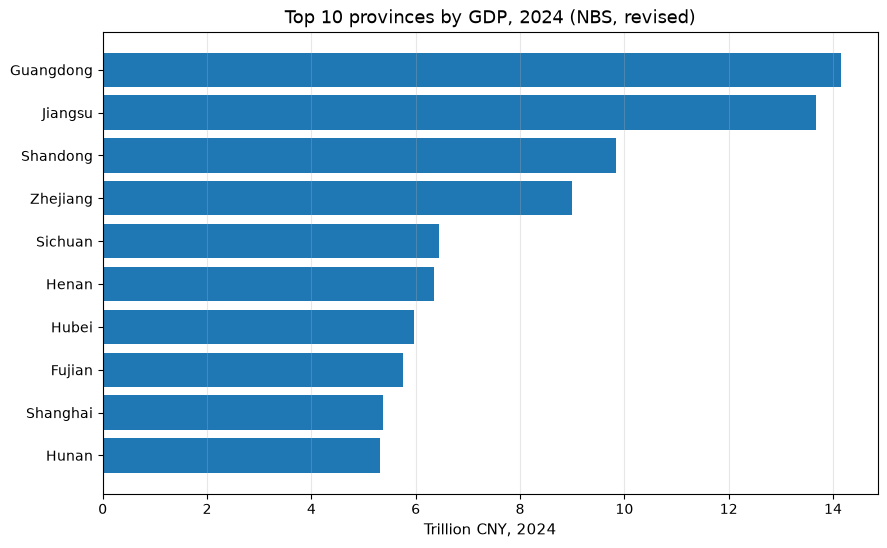

In [3]:

fig, ax = plt.subplots(figsize=(10, 6))
t10 = prov.sort_values("gdp_2024_m_cny", ascending=True).tail(10)
ax.barh(t10.province, t10.gdp_2024_m_cny / 1e6)
ax.set_xlabel("Trillion CNY, 2024")
ax.set_title("Top 10 provinces by GDP, 2024 (NBS, revised)")
ax.grid(True, axis="x", alpha=0.3)
plt.savefig(f"{CHARTS}/04_top10_gdp.png", dpi=150, bbox_inches="tight")
print("Guangdong plus Jiangsu share of national GDP:",
      round(prov[prov.province.isin(["Guangdong", "Jiangsu"])].share_of_national_2024_pct.sum(), 2), "percent")
print("saved 04_top10_gdp.png")


highest: Beijing 227428 CNY
lowest: Gansu 52249 CNY
ratio: 4.35
saved 04_gdp_per_capita.png


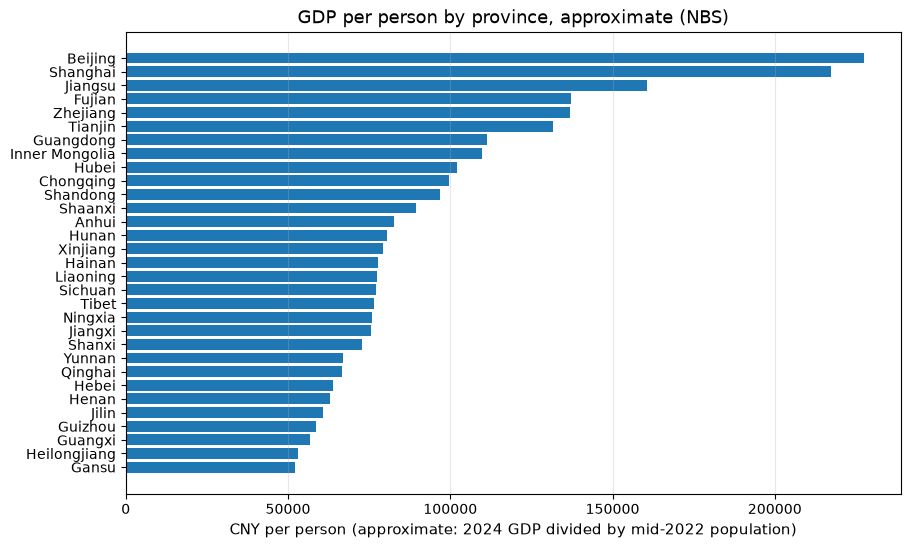

In [4]:

fig, ax = plt.subplots(figsize=(10, 6))
pc = prov.sort_values("gdp_per_capita_2024_approx_cny", ascending=True)
ax.barh(pc.province, pc.gdp_per_capita_2024_approx_cny)
ax.set_xlabel("CNY per person (approximate: 2024 GDP divided by mid-2022 population)")
ax.set_title("GDP per person by province, approximate (NBS)")
ax.grid(True, axis="x", alpha=0.3)
plt.savefig(f"{CHARTS}/04_gdp_per_capita.png", dpi=150, bbox_inches="tight")
top_pc = pc.iloc[-1]
bot_pc = pc.iloc[0]
print("highest:", top_pc.province, top_pc.gdp_per_capita_2024_approx_cny, "CNY")
print("lowest:", bot_pc.province, bot_pc.gdp_per_capita_2024_approx_cny, "CNY")
print("ratio:", round(top_pc.gdp_per_capita_2024_approx_cny / bot_pc.gdp_per_capita_2024_approx_cny, 2))
print("saved 04_gdp_per_capita.png")


## Who led and who lagged

On size, the coast dominates. Guangdong (14.15 trillion yuan in 2024, 10.50 percent of the national total) and Jiangsu (13.67 trillion, 10.14 percent) together are more than a fifth of the economy. Shandong and Zhejiang follow. The bottom five, Qinghai, Ningxia, Hainan, Tibet, and Gansu, together are smaller than Zhejiang alone.

On GDP per person, the municipalities lead: Beijing (about 227,000 yuan) and Shanghai (about 217,000 yuan), then Jiangsu, Fujian, and Zhejiang. The lowest are Gansu (about 52,000 yuan), Heilongjiang (about 53,000), and Guangxi (about 57,000). The top to bottom ratio is about 4.4 to 1. That gap is the regional inequality problem the plans keep trying to narrow.

On 2025 growth (preliminary), Tibet grew fastest at 7.0 percent, and Liaoning slowest at 3.7 percent. Fast growth in a small western province and slow growth in the old industrial northeast is a pattern worth watching: the northeast, once the industrial heartland, has lagged for a decade as heavy industry and population loss bite.

On urbanization (mid-2022), Shanghai (89.3 percent) and Beijing (87.6 percent) are the most urban, and Tibet (37.4 percent) the least, followed by Gansu and Yunnan. Henan, the third most populous province, is only 55.7 percent urban, which is why it still has one of the largest rural populations in the country.

most urban: Shanghai 89.3
least urban: Tibet 37.4
saved 04_urbanization.png


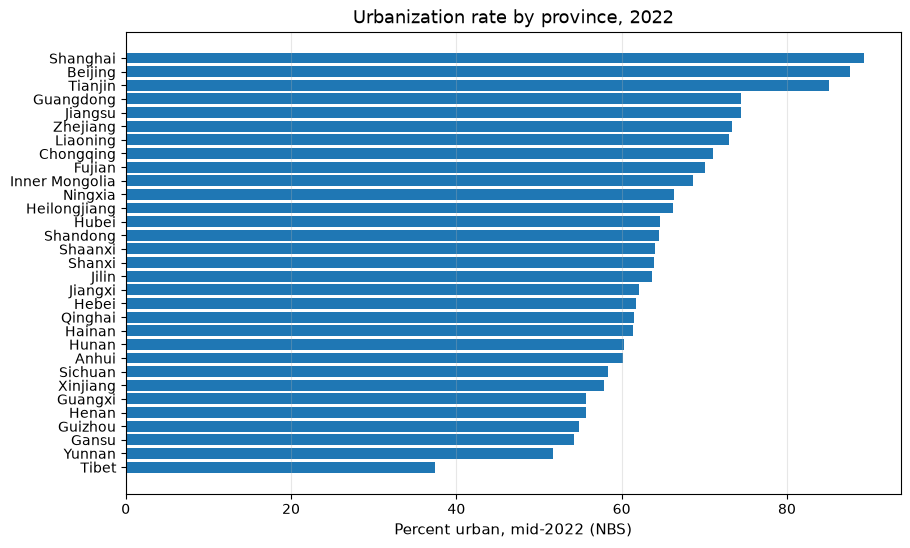

In [5]:

fig, ax = plt.subplots(figsize=(10, 6))
u = prov.sort_values("urban_rate_2022_pct", ascending=True)
ax.barh(u.province, u.urban_rate_2022_pct)
ax.set_xlabel("Percent urban, mid-2022 (NBS)")
ax.set_title("Urbanization rate by province, 2022")
ax.grid(True, axis="x", alpha=0.3)
plt.savefig(f"{CHARTS}/04_urbanization.png", dpi=150, bbox_inches="tight")
print("most urban:", u.iloc[-1].province, u.iloc[-1].urban_rate_2022_pct)
print("least urban:", u.iloc[0].province, u.iloc[0].urban_rate_2022_pct)
print("saved 04_urbanization.png")


      province  gdp_multiple_2000_to_2024
         Hubei                       16.7
       Jiangxi                       16.9
Inner Mongolia                       17.0
     Chongqing                       17.4
       Ningxia                       18.5
       Shaanxi                       19.4
       Guizhou                       21.8
         Tibet                       23.5
saved 04_growth_since_2000.png


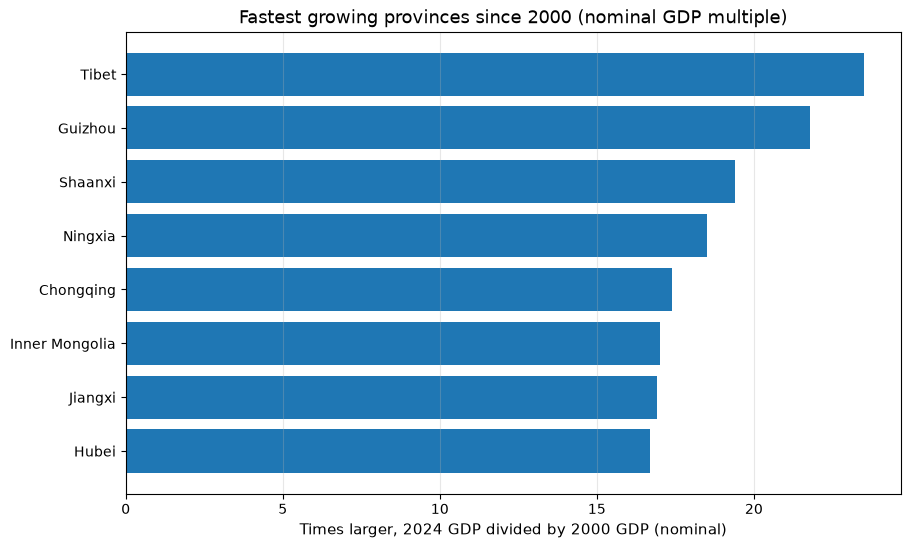

In [6]:

fig, ax = plt.subplots(figsize=(10, 6))
m = prov.sort_values("gdp_multiple_2000_to_2024", ascending=True).tail(8)
ax.barh(m.province, m.gdp_multiple_2000_to_2024)
ax.set_xlabel("Times larger, 2024 GDP divided by 2000 GDP (nominal)")
ax.set_title("Fastest growing provinces since 2000 (nominal GDP multiple)")
ax.grid(True, axis="x", alpha=0.3)
plt.savefig(f"{CHARTS}/04_growth_since_2000.png", dpi=150, bbox_inches="tight")
print(m[["province", "gdp_multiple_2000_to_2024"]].to_string(index=False))
print("saved 04_growth_since_2000.png")


## What this scorecard cannot show: the honest gaps

- Energy intensity by province: no single public comparable table was found in this build. Provinces had different energy targets in the 11th, 12th, and 13th plans, but a clean current table was not available, so it is not charted.
- Research spending by province: same problem. National research spending is known, but a comparable provincial table was not found, so it is not charted.
- 2024 provincial populations: not fetched, so per person GDP uses mid-2022 populations and is labeled approximate.
- Hong Kong and Macau are not in the provincial table. They are special administrative regions with separate statistical systems. Their 2025 GDP figures (Hong Kong 3.05 trillion yuan, Macau 0.37 trillion yuan on the same compilation) are noted here for completeness, not mixed into the mainland ranking.

Next: notebook 05 looks at who lives where, and how the population is changing.